# Självstudieövningar – Vecka 5

De här övningarna är till för att du ska repetera och befästa det vi har gått igenom under veckan samt introducera några nya begrepp på ett tryggt sätt.

Det innebär att vissa av uppgifterna kan du behöva söka efter information själv hur du löser. Här kan du använda Google eller AI om du vill men dokumentationerna är din bästa vän när du lär dig.
- Python: https://docs.python.org/3.13/
- Matplotlib: https://matplotlib.org/stable/
- Pandas: https://pandas.pydata.org/
- NumPy: https://numpy.org/

Läs först igenom vad som ska göras i respektive uppgift och fyll sedan i kodblocket nedanför, eller gör uppgiften i en separat fil.

**Detta lämnas inte in för rättning.** Arbeta i din egen takt, testa dig fram, använd dokumentationen när du kör fast och ta med eventuella frågor till nästa lektionstillfälle.

## (Kör först) Skapa veckans dataset

In [18]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(123)

n = 800
cities = np.array(["Göteborg","Malmö","Stockholm","Uppsala"])
genders = np.array(["F","M"])
groups = np.array(["A","B"])  # för A/B-experiment

city = rng.choice(cities, size=n, p=[0.28, 0.22, 0.40, 0.10])
gender = rng.choice(genders, size=n)
age = rng.integers(18, 65, size=n)

# A/B-tilldelning (balanced med lite slump)
group = rng.choice(groups, size=n)

# Aktivitet (ungefär som "engagement score")
base = rng.normal(60, 12, size=n)

# Små effekter från stad/kön
city_shift = {"Göteborg":2, "Malmö":-1, "Stockholm":1, "Uppsala":0}
gender_shift = {"F":1.5, "M":0}
score = base + np.vectorize(city_shift.get)(city) + np.vectorize(gender_shift.get)(gender)

# Effekt av grupp: B ger +2 i snitt
score = score + np.where(group=="B", 2.0, 0.0)

# Begränsa och runda
score = np.clip(score, 10, 100)

# Binärt utfall (t.ex. "köp"): sannolikhet ökar med score
p_buy = 1/(1 + np.exp(-(score-55)/10))
purchase = rng.binomial(1, p_buy)

# Intäkter för köp (lognormal-ish), 0 om inget köp
revenue = np.where(purchase==1, rng.lognormal(mean=3.2, sigma=0.5, size=n), 0.0)

# Lägg in lite saknade värden
df = pd.DataFrame({
    "city": city,
    "gender": gender,
    "age": age,
    "group": group,
    "score": np.round(score,1),
    "purchase": purchase,
    "revenue": np.round(revenue,2)
})
mask = rng.random(size=df.shape) < 0.01  # ~1% NaN
for (r,c),m in np.ndenumerate(mask):
    if m:
        df.iat[r,c] = np.nan

df.to_csv("customer_activity.csv", index=False)
print("Skapade customer_activity.csv med", len(df), "rader.")

Skapade customer_activity.csv med 800 rader.


### Om datasetet (`customer_activity.csv`)

Det här är ett syntetiskt dataset från en fiktiv digital tjänst. Varje rad representerar en kundobservation.

| Kolumn | Typ | Beskrivning |
|---|---|---|
| `city` | kategori | Kundens stad |
| `gender` | kategori | Kön (F/M) |
| `age` | heltal | Ålder |
| `group` | kategori | Grupp A eller B |
| `score` | decimaltal | Aktivitet eller engagemang, 10–100 |
| `purchase` | 0/1 | Om kunden genomförde ett köp |
| `revenue` | decimaltal | Intäkt, 0 om inget köp genomfördes |

Grupp B har en liten positiv effekt på `score`. Sannolikheten för ett köp ökar med högre `score`. Datasetet innehåller även några saknade värden för att ge möjlighet att öva datarengöring.

Eftersom datasetet är syntetiskt ska det användas för att träna analysmetoder. Resultaten beskriver inte verkliga kunder.

### Snabb kontroll

- Läs in `customer_activity.csv` i en DataFrame som heter `df`.
- Visa de första raderna.
- Kontrollera datatyperna.
- Räkna antalet saknade värden per kolumn.
- Skriv en kort kommentar om något du reagerar på, exempelvis att `revenue` ofta är 0 eftersom alla kunder inte har genomfört ett köp.

In [19]:
import pandas as pd

df = pd.read_csv("customer_activity.csv")
display(df.head())
df.info()
print(df.isna().sum())

,city,gender,age,group,score,purchase,revenue
0,Stockholm,F,57.0,B,86.8,1.0,17.78
1,Göteborg,F,34.0,A,78.1,1.0,27.31
2,Göteborg,M,56.0,B,67.9,0.0,0.00
3,Göteborg,M,27.0,A,45.4,0.0,0.00
4,Göteborg,F,59.0,A,73.5,1.0,12.01


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   city      795 non-null    str    
 1   gender    788 non-null    str    
 2   age       791 non-null    float64
 3   group     792 non-null    str    
 4   score     792 non-null    float64
 5   purchase  793 non-null    float64
 6   revenue   789 non-null    float64
dtypes: float64(4), str(3)
memory usage: 43.9 KB
city         5
gender      12
age          9
group        8
score        8
purchase     7
revenue     11
dtype: int64


## Block A – Fördjupning i Matplotlib

### Uppgift 1 – Tema, grid och etiketter
Rita en valfri figur över `score` (t.ex. histogram eller KDE) och förbättra läsbarheten:
- lägg till titel, axelrubriker, rutnät,
- justera tick-etiketter om det behövs,
- (tips: `plt.style.use(...)`, `plt.grid(True)`, `plt.xticks(rotation=...)`).

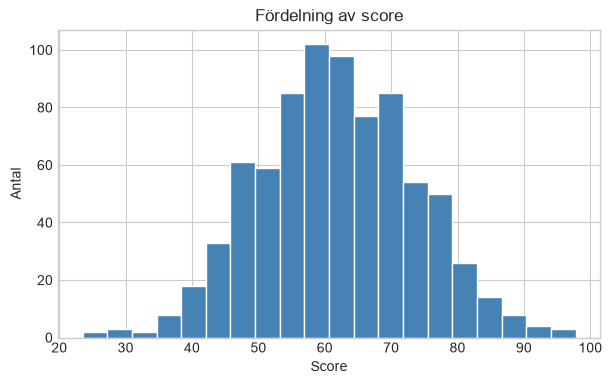

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("customer_activity.csv")
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df["score"].dropna(), bins=20, color="steelblue", edgecolor="white")
ax.set(title="Fördelning av score", xlabel="Score", ylabel="Antal")
# ax.grid(True, axis="y", alpha=0.4)
plt.show()


### Uppgift 2 – Flera paneler (subplots)
Gör två subplots bredvid varandra:
- till vänster: histogram av `score`,
- till höger: stapeldiagram över frekvens per `city`.
Se till att layouter inte överlappar (tips: `plt.tight_layout()`).

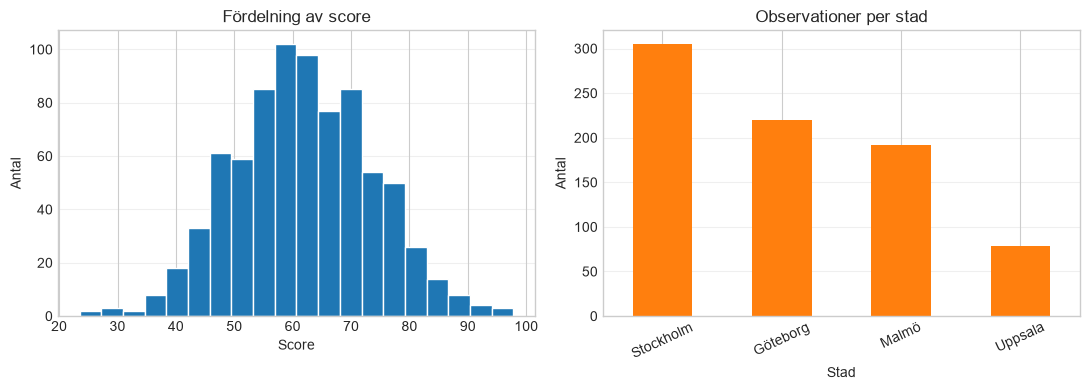

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("customer_activity.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["score"].dropna(), bins=20, color="tab:blue", edgecolor="white")
axes[0].set(title="Fördelning av score", xlabel="Score", ylabel="Antal")
axes[0].grid(True, axis="y", alpha=0.3)

df["city"].value_counts().plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set(title="Observationer per stad", xlabel="Stad", ylabel="Antal")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Uppgift 3 – Färger och annoteringar
Rita en boxplot av `score` uppdelad på `group` och:
- färgsätt grupperna olika,
- lägg in en **horisontell referenslinje** vid `score = 60`,
- annotera grafen med en kort textpil som pekar på en intressant del.
*(tips: `ax.axhline(...)`, `ax.annotate(...)`)*

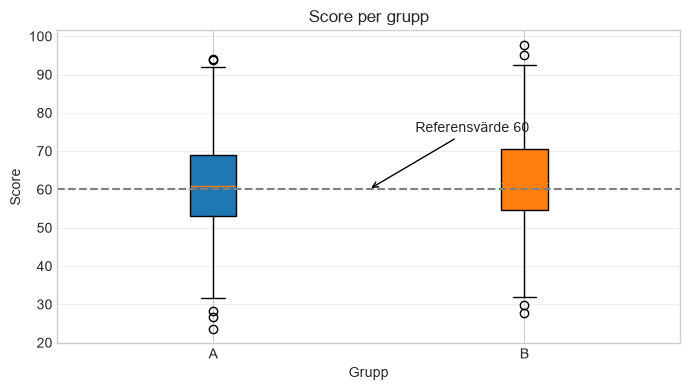

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("customer_activity.csv")
group_a = df.loc[df["group"] == "A", "score"].dropna()
group_b = df.loc[df["group"] == "B", "score"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
box = ax.boxplot([group_a, group_b], tick_labels=["A", "B"], patch_artist=True)
box["boxes"][0].set_facecolor("tab:blue")
box["boxes"][1].set_facecolor("tab:orange")
ax.axhline(60, color="gray", linestyle="--")
ax.annotate("Referensvärde 60", xy=(1.5, 60), xytext=(1.65, 75),
            arrowprops={"arrowstyle": "->"})
ax.set(title="Score per grupp", xlabel="Grupp", ylabel="Score")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Uppgift 4 – Felsökning: filnamn, legend och etiketter

Koden ska jämföra fördelningen av `score` i grupp A och grupp B, men den innehåller flera problem. Kör koden, undersök felmeddelanden och rätta den.

```python
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("weekX_data.csv")

group_a = df.loc[df["group"] == "A", "score"].dropna()
group_b = df.loc[df["group"] == "B", "score"].dropna()

fig, ax = plt.subplots()

ax.hist(group_a, bins=20, alpha=0.6, label="Grupp A")
ax.hist(group_b, bins=20, alpha=0.6)

ax.legend()
plt.show()
```

När koden är rättad ska den:

- läsa in rätt fil,
- visa båda grupperna i legenden,
- ha en beskrivande titel,
- ha tydliga axelrubriker,
- använda färger eller transparens så att grupperna går att jämföra.

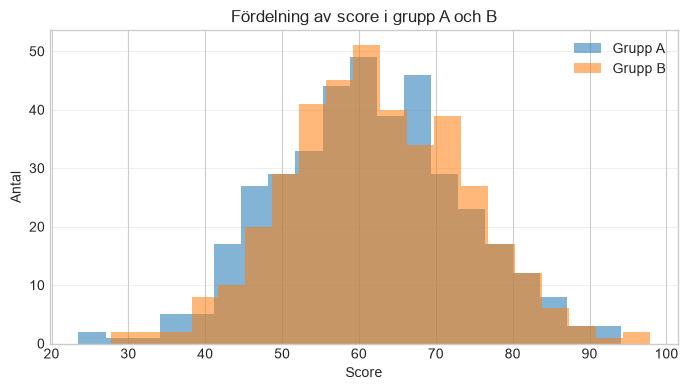

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("customer_activity.csv")
group_a = df.loc[df["group"] == "A", "score"].dropna()
group_b = df.loc[df["group"] == "B", "score"].dropna()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(group_a, bins=20, alpha=0.55, color="tab:blue", label="Grupp A")
ax.hist(group_b, bins=20, alpha=0.55, color="tab:orange", label="Grupp B")
ax.set(title="Fördelning av score i grupp A och B", xlabel="Score", ylabel="Antal")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Uppgift 5 – Välj rätt figur
Du vill jämföra distributionen av `revenue` mellan `group` **för de som köpt** (`purchase==1`). 
- Välj en **lämplig** figurtyp (motivera kort i en kommentar).
- Rita grafen och gör den läsbar (titel, axlar, grid).

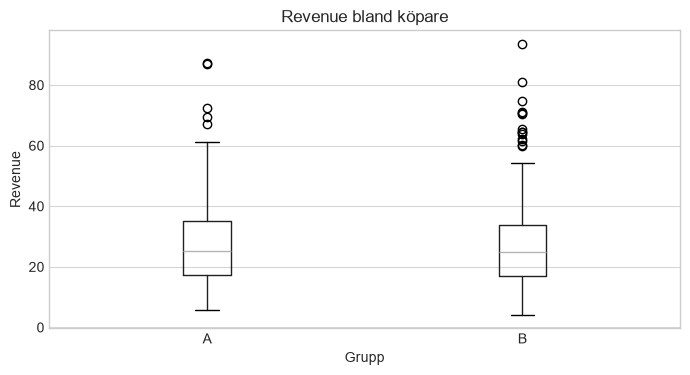

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("customer_activity.csv")
paid = df.loc[df["purchase"] == 1, ["group", "revenue"]].dropna()

fig, ax = plt.subplots(figsize=(7, 4))
paid.boxplot(column="revenue", by="group", ax=ax, grid=False)
ax.set(title="Revenue bland köpare", xlabel="Grupp", ylabel="Revenue")
ax.grid(True, axis="y", alpha=0.8)
plt.suptitle("")
plt.tight_layout()
plt.show()

## Block B – EDA med Python

### Uppgift 6 – Grundprofil
- Räkna frekvens per `city` och `gender`.
- Räkna andel som köpt (`purchase`-medel fungerar här) per `city`.
- Skapa en tabell med medel/median för `score` och `revenue` per `group` och `gender`.
*(tips: `groupby(...).agg({...})`)*

In [25]:
import pandas as pd

df = pd.read_csv("customer_activity.csv")
print("Frekvens per city:\n", df["city"].value_counts())
print("\nFrekvens per gender:\n", df["gender"].value_counts())
print("\nKöpandel per city:\n", df.groupby("city")["purchase"].mean())

summary = (
    df.groupby(["group", "gender"])
      .agg(
          score_mean=("score", "mean"),
          score_median=("score", "median"),
          revenue_mean=("revenue", "mean"),
          revenue_median=("revenue", "median"),
      )
)
summary

Frekvens per city:
 city
Stockholm    305
Göteborg     220
Malmö        192
Uppsala       78
Name: count, dtype: int64

Frekvens per gender:
 gender
M    422
F    366
Name: count, dtype: int64

Köpandel per city:
 city
Göteborg     0.619266
Malmö        0.603175
Stockholm    0.664474
Uppsala      0.727273
Name: purchase, dtype: float64


score_mean  score_median  revenue_mean  revenue_median
group gender                                                        
A     F        61.861932         60.20     16.810289           15.97
      M        60.765421         61.05     18.570372           17.48
B     F        61.390659         61.00     17.926209           16.25
      M        62.864500         62.25     17.779350           16.57

### Uppgift 7 – Samband mellan variabler
- Skapa ett **spridningsdiagram** med `score` (x) och `revenue` (y) **endast för köp**.
- Lägg gärna på en enkel trendlinje eller glidande medelvärde (valfritt).
- Kommentera om sambandet ser linjärt ut eller ej.

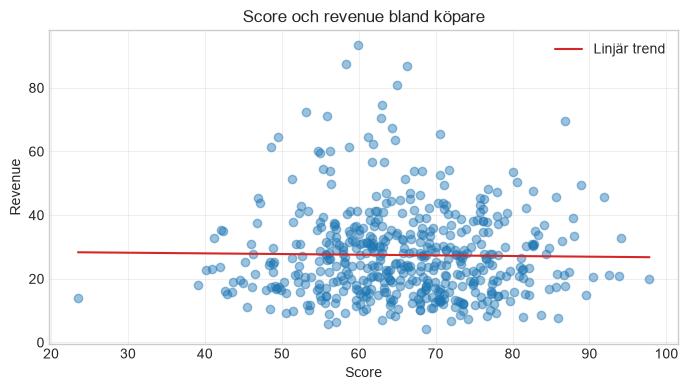

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("customer_activity.csv")
paid = df.loc[df["purchase"] == 1, ["score", "revenue"]].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(paid["score"], paid["revenue"], alpha=0.45)

slope, intercept = np.polyfit(paid["score"], paid["revenue"], 1)
x_line = np.linspace(paid["score"].min(), paid["score"].max(), 100)
ax.plot(x_line, intercept + slope * x_line, color="tab:red", label="Linjär trend")
ax.set(title="Score och revenue bland köpare", xlabel="Score", ylabel="Revenue")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Uppgift 8 – Rensa saknade värden
- Räkna saknade värden per kolumn.
- Fyll saknade i `age` med median; i `score` med medelvärde.
- Verifiera att saknade minskat.
*(tips: `fillna(...)`)*

In [27]:
import pandas as pd

df = pd.read_csv("customer_activity.csv")
print("Före:\n", df.isna().sum())
df["age"] = df["age"].fillna(df["age"].median())
df["score"] = df["score"].fillna(df["score"].mean())
print("\nEfter:\n", df.isna().sum())

Före:
 city         5
gender      12
age          9
group        8
score        8
purchase     7
revenue     11
dtype: int64

Efter:
 city         5
gender      12
age          0
group        8
score        0
purchase     7
revenue     11
dtype: int64


### Uppgift 9 – Mini-EDA

Genomför en mindre utforskande dataanalys av `customer_activity.csv`.

#### 1. Formulera frågor

Välj minst tre frågor som du vill undersöka. Du kan exempelvis undersöka:

- Skiljer sig `score` mellan grupp A och grupp B?
- Verkar kunder med högre `score` köpa oftare?
- Skiljer sig köpfrekvensen mellan olika städer?
- Hur ser fördelningen av `revenue` ut bland kunder som har genomfört ett köp?
- Finns det något synligt samband mellan ålder och `score`?

Du får formulera egna frågor.

#### 2. Kontrollera och förbered data

- kontrollera datatyper och saknade värden,
- avgör vilka saknade värden som behöver hanteras,
- filtrera data när det behövs för analysen,
- dokumentera kort vilka beslut du fattar.

#### 3. Sammanfatta data

Använd lämpliga sammanfattningar, exempelvis:

- antal och andelar,
- medelvärde och median,
- gruppering med `groupby()`,
- frekvenstabeller.

#### 4. Visualisera

Skapa minst tre visualiseringar som hjälper dig att besvara frågorna.

Välj figurtyp utifrån vilken typ av fråga och vilka variabler du undersöker. Varje figur ska ha:

- en tydlig titel,
- relevanta axelrubriker,
- läsbar skala och layout,
- en legend när den behövs.

Spara minst en figur som en bildfil.

#### 5. Sammanfatta dina observationer

Skriv 3–5 korta observationer från analysen. Skilj mellan:

- vad som faktiskt syns i data,
- möjliga förklaringar som skulle behöva undersökas vidare.

Undvik att beskriva samband som orsakssamband om analysen inte ger stöd för det.

Score per grupp:
        count       mean  median
group                          
A        396  61.283818   61.05
B        396  62.260488   61.80

Köpandel per stad:
 city
Uppsala      0.727273
Stockholm    0.664474
Göteborg     0.619266
Malmö        0.603175
Name: purchase, dtype: float64

Revenue bland köpare:
 count    504.000000
mean      27.530298
std       13.982778
min        4.120000
25%       17.260000
50%       24.975000
75%       34.242500
max       93.550000
Name: revenue, dtype: float64


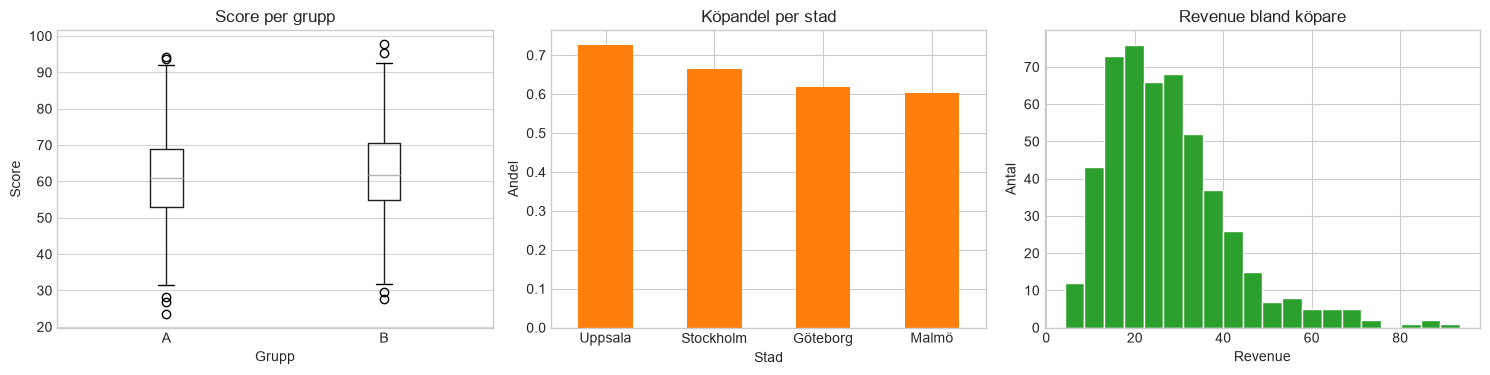

1. Grupp B har 0.977 högre genomsnittlig score än grupp A i detta dataset.
2. Högst observerad köpandel finns i Uppsala (72.7%).
3. Median revenue bland köpare är 24.98.
4. Skillnaderna är beskrivande samband. möjliga orsaker kräver en separat undersökning.


In [28]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("customer_activity.csv")
analysis = df.copy()
analysis["age"] = analysis["age"].fillna(analysis["age"].median())
analysis["score"] = analysis["score"].fillna(analysis["score"].mean())

score_by_group = analysis.dropna(subset=["group"]).groupby("group")["score"].agg(["count", "mean", "median"])
print("Score per grupp:\n", score_by_group)

purchase_by_city = analysis.dropna(subset=["city", "purchase"]).groupby("city")["purchase"].mean().sort_values(ascending=False)
print("\nKöpandel per stad:\n", purchase_by_city)

paid = analysis.loc[analysis["purchase"] == 1, "revenue"].dropna()
print("\nRevenue bland köpare:\n", paid.describe())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
analysis.dropna(subset=["group"]).boxplot(column="score", by="group", ax=axes[0], grid=False)
axes[0].set(title="Score per grupp", xlabel="Grupp", ylabel="Score")
axes[0].grid(True, axis="y", alpha=0.8)

purchase_by_city.plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set(title="Köpandel per stad", xlabel="Stad", ylabel="Andel")
axes[1].tick_params(axis="x", rotation=0)

axes[2].hist(paid, bins=20, color="tab:green", edgecolor="white")
axes[2].set(title="Revenue bland köpare", xlabel="Revenue", ylabel="Antal")

# for axis in axes:
#     axis.grid(True, axis="y", alpha=0.6)

plt.suptitle("")
plt.tight_layout()
plt.show()

group_diff = score_by_group.loc["B", "mean"] - score_by_group.loc["A", "mean"]
print(f"1. Grupp B har {group_diff:.3f} högre genomsnittlig score än grupp A i detta dataset.")
print(f"2. Högst observerad köpandel finns i {purchase_by_city.index[0]} ({purchase_by_city.iloc[0]:.1%}).")
print(f"3. Median revenue bland köpare är {paid.median():.2f}.")
print("4. Skillnaderna är beskrivande samband. möjliga orsaker kräver en separat undersökning.")